# House Price Prediction — Modelling Pipeline

**Course:** Machine Learning, Concept Integration Assessment 2 (BITS Pilani Dubai)  
**Team:** Nabhya Yadav, MVS Maheedhar Reddy, Nivedita Mahesh, Ponnamanda Hruday Manas

This notebook runs the full pipeline on the Ames Housing data (Kaggle `train.csv`), from setup to the final test-set evaluation. Each section starts with a short note covering **what** the step does, **why** it is needed and **what to look for** in the output.

To rebuild everything in a fresh Colab session, use **Runtime → Run all**.

## 0. Setup

**What:** installs the libraries Colab may lack, imports everything, and downloads `train.csv` into `data/`.

**Why:** Colab sessions are temporary, so every file in `/content/` is deleted when the session ends. Putting all setup at the top means one "Run all" rebuilds the session from nothing. We fix a random seed (`RANDOM_STATE = 42`) so the split and every model give the same results on every run (reproducibility).

**What to look for:** the printed library versions (scikit-learn must be **≥ 1.4** for `TargetEncoder`), and a confirmation that `data/train.csv` exists.

In [33]:
# Install or upgrade the libraries we rely on.
# %pip (not !pip) installs into the kernel this notebook is running on.
# scikit-learn >= 1.4 is required for TargetEncoder (Neighborhood encoding, later).
# -q keeps the install log short.
%pip install -q "scikit-learn>=1.4" "xgboost>=2.0" "shap>=0.44" "gdown>=5.0"

In [53]:
import os

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# xgboost and shap are only used in later sections. Importing them here
# means a failed install shows up in the first minute, not at the end of the run.
import shap
import xgboost

# One seed for every random step (split, CV folds, models) so results are reproducible.
RANDOM_STATE = 42

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgboost.__version__)
print("shap        :", shap.__version__)

pandas      : 2.2.3
numpy       : 2.4.6
scikit-learn: 1.6.1
xgboost     : 3.4.1
shap        : 0.54.1


In [35]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "train.csv")
# Shared Google Drive copy of Kaggle's train.csv (the CSV is not committed to git:
# Kaggle's competition rules restrict redistribution).
DRIVE_FILE_ID = "1kh3Fz_JmR75a22_1mxfcWMRTRcHGK-iA"

# Create the folders the rest of the notebook writes into.
for folder in [DATA_DIR, "outputs/figures", "outputs/results"]:
    os.makedirs(folder, exist_ok=True)

# Download only if the file is missing, so re-running this cell does not re-download it.
if not os.path.exists(DATA_PATH):
    gdown.download(id=DRIVE_FILE_ID, output=DATA_PATH, quiet=False)

print("train.csv present:", os.path.exists(DATA_PATH))

train.csv present: True


## 1. Load the data

**What:** reads `train.csv`, drops `Id`, converts `MSSubClass` to text, and separates the **features** (the inputs, `X`) from the **target** (the value we predict, `y`).

**Why:**
- `Id` is just a row number. Keeping it would let a model find accidental patterns in it.
- `MSSubClass` is stored as a number (20, 60, 190, ...), but each number is a code for a dwelling type. Type 60 is not "three times" type 20. Storing it as text makes the pipeline treat it as a **categorical** feature (one-hot encoded later) instead of a quantity.
- The target is `log(1 + SalePrice)`. In EDA, `SalePrice` was strongly right-skewed (skew 1.88); after the log it is almost symmetric (skew 0.12). Kaggle's metric is also RMSE on log price. Predictions are converted back to dollars later with `np.expm1`.

**What to look for:** shape `(1460, 80)` after dropping `Id`; `MSSubClass` dtype `object` (pandas' text type); 79 feature columns.

In [36]:
def load_data(path):
    """Load the Ames training data and apply the type decisions made in EDA.

    Input:  path to Kaggle's train.csv.
    Output: DataFrame without the Id column, with MSSubClass stored as text.
    """
    df = pd.read_csv(path)
    # Id is a row number with no information about the house.
    df = df.drop(columns="Id")
    # MSSubClass is a dwelling-type code, not a quantity, so treat it as categorical.
    df["MSSubClass"] = df["MSSubClass"].astype(str)
    return df


df = load_data(DATA_PATH)

# Features = every column except the price. Target = log price (skew 1.88 -> 0.12 in EDA).
X = df.drop(columns="SalePrice")
y_log = np.log1p(df["SalePrice"])

print("Data shape (rows, columns):", df.shape)
print("Number of features        :", X.shape[1])
print("MSSubClass dtype          :", df["MSSubClass"].dtype)
print("Skew of log price         :", round(y_log.skew(), 2))

Data shape (rows, columns): (1460, 80)
Number of features        : 79
MSSubClass dtype          : object
Skew of log price         : 0.12


**Result:** after dropping `Id`, the data has 1,460 rows and 80 columns (79 features plus `SalePrice`). `MSSubClass` is stored as text (`object`), so it will be one-hot encoded instead of treated as a number. The skew of the log target is 0.12, the same as in EDA, which confirms the target is close to symmetric.

## 2. Train / test split (80 / 20, stratified on price)

**What:** sets aside 20% of the houses as a **test set** that no step touches until the final evaluation. The other 80% is the **training set**, used for every later decision: imputation statistics, encodings, scaling, outlier removal, cross-validation and tuning.

**Why split first:** if any statistic (a median, an encoding, a scaler) were computed on all 1,460 houses, information about the test houses would leak into training. The test score would then look better than the model really is. This is called **data leakage**. Splitting before anything else prevents it.

**Why stratify:** a purely random split of 1,460 houses could, by chance, put too many expensive or cheap houses on one side. We cut log price into 10 equal-sized bins (**deciles**) and ask `train_test_split` to keep each bin's share the same in both sets. Both sets then cover the same price range.

*Note:* the bins use price only to decide which rows go where. Nothing learned from them is passed to a model, so this is not leakage.

**What to look for:** 1,168 training and 292 test houses; very similar price summaries (mean, quartiles, min, max) in the two columns.

In [37]:
TEST_SIZE = 0.2      # 80% train / 20% test
N_STRAT_BINS = 10    # deciles of log price: covers the price range, about 146 houses per bin

# Label each house with its price decile (0 = cheapest 10%, 9 = most expensive 10%).
price_bins = pd.qcut(y_log, q=N_STRAT_BINS, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_log,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=price_bins,  # same share of each price decile in train and test
)

print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)

# Compare the price distributions (in dollars) to confirm the stratification worked.
price_summary = pd.DataFrame({
    "train (USD)": np.expm1(y_train).describe(),
    "test (USD)": np.expm1(y_test).describe(),
}).round(0)
print("\nSalePrice summary by split:")
print(price_summary)

Training set: (1168, 79)
Test set    : (292, 79)

SalePrice summary by split:
       train (USD)  test (USD)
count       1168.0       292.0
mean      180977.0    180698.0
std        79285.0     80205.0
min        34900.0     35311.0
25%       129975.0    129750.0
50%       163000.0    163495.0
75%       213625.0    214875.0
max       755000.0    625000.0


**Result:** 1,168 houses are in the training set and 292 in the test set (80 / 20). The two price distributions are almost identical. The means are \$180,977 (train) and \$180,698 (test), and the medians are \$163,000 and \$163,495. All three quartiles are within \$1,250 of each other, so the stratification worked.

The maximum differs: \$755,000 in train and \$625,000 in test. Stratifying on deciles balances how many houses fall in each price band, not the single most extreme values. The top band is very wide, so one or two very expensive houses can land on either side. This means no test house costs more than the most expensive training house, which is fine for evaluation.

From here until the final evaluation, the test set is not used again.

## 3. Outliers in the training set

**What:** plots above-ground living area (`GrLivArea`) against sale price for the **training set only**, and flags houses with `GrLivArea > 4000` sq ft **and** `SalePrice < $300,000`. Nothing is removed yet. This step only shows the candidates so we can confirm the rule.

**Why:** living area is one of the strongest predictors of price. Usually, a very large house sells for a very high price. A huge house sold cheaply breaks that pattern. De Cock (2011), who published the Ames dataset, notes that houses over 4,000 sq ft include partial sales (sold before construction finished) that do not reflect market value, and recommends removing them. A few such points can pull a linear model's fitted line towards them, which makes predictions worse for normal houses. An **outlier** is a data point far from the general pattern.

**Why the training set only:** outlier removal is a decision learned from data, like any other preprocessing step. The test set must stay as it is, because real houses we predict for later will not have been filtered.

**What to look for:** red points in the bottom-right corner (large area, low price), far from the main trend. Check the `SaleCondition` of each flagged house: `Partial` means a partial sale. Also look at large houses that sold at **high** prices. They follow the trend, so they are kept.

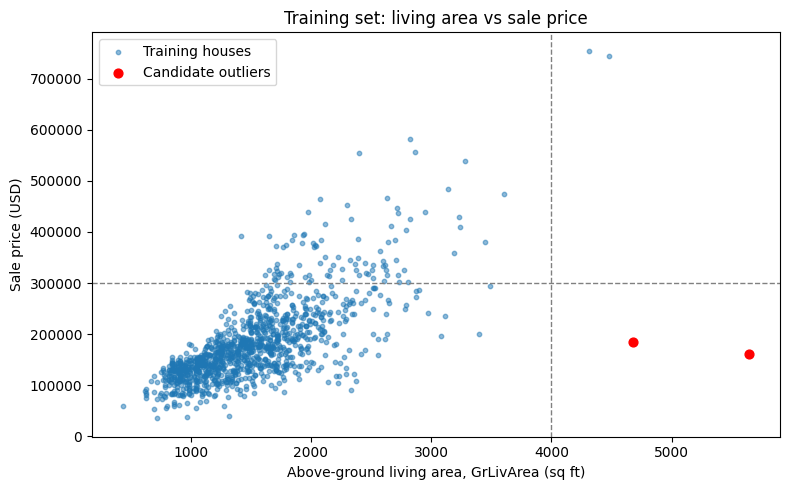

Training houses with GrLivArea > 4000 sq ft: 4
Of these, flagged as outliers           : 2

      GrLivArea SaleCondition  SalePrice (USD)  Flagged
691        4316        Normal         755000.0    False
1182       4476       Abnorml         745000.0    False
523        4676       Partial         184750.0     True
1298       5642       Partial         160000.0     True


In [38]:
# Thresholds from De Cock (2011) and our EDA scatter plot.
OUTLIER_MIN_AREA = 4000      # above-ground living area, sq ft
OUTLIER_MAX_PRICE = 300000   # sale price, USD

# Work in dollars here: the rule is stated in dollars, and dollars are easier to read on a plot.
train_price = np.expm1(y_train)

# A candidate outlier is very large AND cheap: it breaks the "bigger house -> higher price" trend.
is_outlier = (X_train["GrLivArea"] > OUTLIER_MIN_AREA) & (train_price < OUTLIER_MAX_PRICE)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train.loc[~is_outlier, "GrLivArea"], train_price[~is_outlier],
           s=10, alpha=0.5, label="Training houses")
ax.scatter(X_train.loc[is_outlier, "GrLivArea"], train_price[is_outlier],
           s=40, color="red", label="Candidate outliers")
# Dashed lines mark the two thresholds of the rule.
ax.axvline(OUTLIER_MIN_AREA, color="grey", linestyle="--", linewidth=1)
ax.axhline(OUTLIER_MAX_PRICE, color="grey", linestyle="--", linewidth=1)
ax.set_title("Training set: living area vs sale price")
ax.set_xlabel("Above-ground living area, GrLivArea (sq ft)")
ax.set_ylabel("Sale price (USD)")
ax.legend()
fig.tight_layout()
fig.savefig("outputs/figures/train_grlivarea_vs_saleprice.png", dpi=150)
plt.show()

# Show the flagged houses, and every large house, so the rule can be judged house by house.
large_houses = X_train.loc[X_train["GrLivArea"] > OUTLIER_MIN_AREA, ["GrLivArea", "SaleCondition"]].copy()
large_houses["SalePrice (USD)"] = train_price[large_houses.index].round(0)
large_houses["Flagged"] = is_outlier[large_houses.index]
print("Training houses with GrLivArea > 4000 sq ft:", len(large_houses))
print("Of these, flagged as outliers           :", int(is_outlier.sum()))
print()
print(large_houses.sort_values("GrLivArea"))

**Result:** 4 training houses have more than 4,000 sq ft of living area, and 2 of them are flagged.

| Row | GrLivArea (sq ft) | SaleCondition | SalePrice (USD) | Flagged |
|---|---|---|---|---|
| 691 | 4,316 | Normal | 755,000 | No |
| 1182 | 4,476 | Abnorml | 745,000 | No |
| 523 | 4,676 | Partial | 184,750 | Yes |
| 1298 | 5,642 | Partial | 160,000 | Yes |

- Both flagged houses are **partial sales** (sold before construction was finished). This matches De Cock's (2011) explanation: their prices do not reflect market value. Row labels 523 and 1298 are Kaggle `Id`s 524 and 1299, because `Id` = row number + 1.
- The two unflagged large houses sold for \$745,000 or more, so they follow the "bigger house → higher price" trend and are kept. House 1182 is an `Abnorml` sale but is kept anyway: the rule removes houses whose price does not fit their size, not houses with a particular label.
- There is a wide gap between the flagged prices (≤ \$184,750) and the other large houses (≥ \$745,000). Any price threshold inside that gap flags the same two houses, so the result does not depend on the exact choice of \$300,000.
- Both flagged houses are in the training set, so the rule removes them from training. The test set is not filtered.

### 3b. Remove the confirmed outliers from the training set

**What:** drops the 2 flagged houses from `X_train` and `y_train`.

**Why:** the rule was confirmed after looking at the plot and table above. Features and target are filtered with the same row labels, so each remaining house keeps its own price. `X_test` and `y_test` are not touched.

**What to look for:** training set 1,168 → 1,166 houses; the test set still has 292; the feature rows and target values still line up.

In [39]:
def remove_rows(X, y, row_labels):
    """Drop the given rows from both the features and the target.

    Inputs:  X (feature DataFrame), y (target Series), row_labels (index labels to drop).
    Outputs: filtered X and y, still aligned row by row.
    errors="ignore" makes the cell safe to re-run: rows already removed are skipped.
    """
    return X.drop(index=row_labels, errors="ignore"), y.drop(index=row_labels, errors="ignore")


# Take the labels from the mask itself, so this cell does not depend on X_train's current size.
outlier_labels = is_outlier.index[is_outlier]

print("Training set before:", X_train.shape)
X_train, y_train = remove_rows(X_train, y_train, outlier_labels)
print("Training set after :", X_train.shape)
print("Test set (unchanged):", X_test.shape)
print("Removed rows (Kaggle Id):", [int(label) + 1 for label in outlier_labels])
# Features and target must describe the same houses in the same order.
print("X_train and y_train aligned:", X_train.index.equals(y_train.index))

Training set before: (1168, 79)
Training set after : (1166, 79)
Test set (unchanged): (292, 79)
Removed rows (Kaggle Id): [524, 1299]
X_train and y_train aligned: True


## 4. Preprocessing

### 4a. Missing values: a custom imputation transformer

**What:** fills every missing value using the rules decided in EDA:

| Column(s) | Rule | Why |
|---|---|---|
| `PoolQC, MiscFeature, Alley, Fence, FireplaceQu, MasVnrType`, garage and basement categories | the text `"None"` | In this dataset, `NA` means the house **has no** pool, garage, basement, etc. That is real information, not unknown data. |
| `MasVnrArea` | `0` | No masonry veneer means zero veneer area. |
| `LotFrontage` (259 missing) | median of the **same neighbourhood** | Genuinely unknown. Lot widths are similar within a neighbourhood, so the local median is a better guess than the overall median. |
| `Electrical` (1 missing) | most common value (**mode**) | Genuinely unknown; every house has an electrical system. |
| `BsmtExposure`, `BsmtFinType2` for the one house that **has** a basement | mode | This house has a basement, so `"None"` would be wrong. (38 missing vs 37 for the other basement columns.) |
| `GarageYrBlt` | drop the column | 81 missing, and almost always the same year as `YearBuilt`. |

**Why a transformer (a class with `fit` and `transform`):** the neighbourhood medians and the modes are **statistics learned from data**. `fit` learns them from the training set only, and `transform` applies the same values to any data (training, CV folds, test). Later, this transformer goes inside a scikit-learn `Pipeline`. During cross-validation, the pipeline then refits it on each training fold, so no statistic is ever learned from the houses it is evaluated on. This prevents data leakage.

**Why the basement fix comes first:** if every missing basement value were filled with `"None"` first, we could no longer tell the one house that does have a basement apart from the 37 that do not.

In [40]:
# Columns where NA means "the house does not have this feature" (decided in EDA).
NONE_COLS = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
# Basement columns with one extra missing value (38 vs 37): a house that HAS a basement.
BSMT_MODE_COLS = ["BsmtExposure", "BsmtFinType2"]


class AmesImputer(BaseEstimator, TransformerMixin):
    """Fill missing values in the Ames data using the rules decided in EDA.

    fit(X):       learns the neighbourhood LotFrontage medians and the modes, from X only.
    transform(X): returns a copy of X with GarageYrBlt dropped and no missing values
                  in the columns listed above.
    """

    def fit(self, X, y=None):
        # mode() ignores missing values, so these are the most common recorded values.
        self.bsmt_modes_ = {col: X[col].mode()[0] for col in BSMT_MODE_COLS}
        self.electrical_mode_ = X["Electrical"].mode()[0]
        self.lot_frontage_by_nbhd_ = X.groupby("Neighborhood")["LotFrontage"].median()
        # Fallback for a neighbourhood with no known LotFrontage in the training data.
        self.lot_frontage_overall_ = X["LotFrontage"].median()
        return self

    def transform(self, X):
        X = X.copy()  # never change the DataFrame passed in

        # 81 missing and nearly identical to YearBuilt, so it adds little information.
        X = X.drop(columns="GarageYrBlt")

        # Must run before the "None" fill: a house with a basement (BsmtQual recorded)
        # but a missing BsmtExposure/BsmtFinType2 gets the mode, not "None".
        has_basement = X["BsmtQual"].notna()
        for col, mode in self.bsmt_modes_.items():
            X.loc[has_basement & X[col].isna(), col] = mode

        X[NONE_COLS] = X[NONE_COLS].fillna("None")
        X["MasVnrArea"] = X["MasVnrArea"].fillna(0)  # no veneer -> zero area

        # Each house gets its neighbourhood's training median; unseen/empty neighbourhoods
        # fall back to the overall training median.
        nbhd_median = X["Neighborhood"].map(self.lot_frontage_by_nbhd_)
        X["LotFrontage"] = X["LotFrontage"].fillna(nbhd_median).fillna(self.lot_frontage_overall_)

        X["Electrical"] = X["Electrical"].fillna(self.electrical_mode_)
        return X

**Check the imputer.** This cell fits the imputer on the training set and applies it to both sets, only to check that it works. In the final pipeline this happens inside the `Pipeline`, so the transformed copies made here are not used for modelling.

**What to look for:**
- 0 missing values left in both the training and test sets. If the test set still has some, a column there has missing values that the training set did not, and we need a rule for it.
- 78 columns (79 minus `GarageYrBlt`).
- The learned statistics (modes, medians) look sensible.
- `X_train` itself still has its missing values, which shows the transformer works on a copy.

In [41]:
imputer = AmesImputer()
imputer.fit(X_train)  # statistics learned from the training set only
X_train_imp = imputer.transform(X_train)
X_test_imp = imputer.transform(X_test)

print("Missing values before (train):", int(X_train.isna().sum().sum()))
print("Missing values after  (train):", int(X_train_imp.isna().sum().sum()))
print("Missing values after  (test) :", int(X_test_imp.isna().sum().sum()))
print("Columns after imputation     :", X_train_imp.shape[1])
print("X_train still unchanged      :", X_train.isna().any().any())

print("\nLearned from the training set:")
print("  Electrical mode           :", imputer.electrical_mode_)
print("  Basement modes            :", imputer.bsmt_modes_)
print("  LotFrontage overall median:", imputer.lot_frontage_overall_, "ft")
print("  LotFrontage median by neighbourhood (ft), first 5:")
print(imputer.lot_frontage_by_nbhd_.head().round(1).to_string())

Missing values before (train): 6267
Missing values after  (train): 0
Missing values after  (test) : 0
Columns after imputation     : 78
X_train still unchanged      : True

Learned from the training set:
  Electrical mode           : SBrkr
  Basement modes            : {'BsmtExposure': 'No', 'BsmtFinType2': 'Unf'}
  LotFrontage overall median: 70.0 ft
  LotFrontage median by neighbourhood (ft), first 5:
Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0


**Result:** the imputer filled all 6,267 missing values in the training set and left 0 in the test set. So the rules cover every column with gaps, including in houses the imputer did not learn from. 78 columns remain (only `GarageYrBlt` was dropped), and `X_train` itself was not modified.

Values learned from the training set:
- **`Electrical` → `SBrkr`** (standard circuit breakers), the most common wiring type.
- **`BsmtExposure` → `No`** for the house that has a basement. `No` is a real category meaning "a basement with no walkout or garden-level walls", which is different from `"None"` (no basement at all). This is why the basement fix runs before the `"None"` fill.
- **`BsmtFinType2` → `Unf`** (unfinished basement area).
- **`LotFrontage`:** the overall training median is 70 ft, but the neighbourhood medians differ a lot. Among just the first five neighbourhoods alphabetically they range from 21 ft (BrDale) to 80 ft (ClearCr). With a single overall median, a BrDale house would get 70 ft, more than three times its neighbourhood's typical lot width. This supports filling by neighbourhood.

### 4b. Quality columns: ordinal encoding

**What:** converts the 10 quality and condition columns from text grades to numbers that keep their order:

| Grade | `None` | `Po` (Poor) | `Fa` (Fair) | `TA` (Typical/Average) | `Gd` (Good) | `Ex` (Excellent) |
|---|---|---|---|---|---|---|
| Number | 0 | 1 | 2 | 3 | 4 | 5 |

Columns: `ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC`.

**Why ordinal and not one-hot:** these grades have a natural order (Poor < Fair < ... < Excellent). One number per column keeps that order, so a model can learn "better kitchen → higher price" directly. One-hot encoding would split each column into up to 6 unrelated 0/1 columns and throw the order away.

**Assumption to be aware of:** a linear model treats the steps as equal: Fair → Typical counts as much as Good → Excellent. This is a simplification. Tree models (Random Forest, XGBoost) only use the order, not the spacing, so it does not affect them.

**Why a transformer:** there is nothing to learn here (the mapping is fixed), but as a transformer it sits in the same `Pipeline` as the imputer and is applied identically to every CV fold and to the test set. It runs **after** the imputer, which has already turned missing values into `"None"`.

**What to look for:** all 10 columns become numbers (`int64`), with no missing values. In the `KitchenQual` cross-table, each grade should appear under exactly one number (e.g. every `Gd` under `4`).

In [42]:
# Ordered quality grades used throughout the Ames data documentation.
QUALITY_MAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUALITY_COLS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]


class QualityEncoder(BaseEstimator, TransformerMixin):
    """Map quality grades (None/Po/Fa/TA/Gd/Ex) to 0-5 in the quality columns.

    fit(X):       nothing to learn (the mapping is fixed); returns self.
    transform(X): returns a copy of X with QUALITY_COLS as integers 0-5.
    Must run after AmesImputer, so missing values are already "None".
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for col in QUALITY_COLS:
            mapped = X[col].map(QUALITY_MAP)
            # A grade outside the map would silently become NaN; stop with a clear message instead.
            unknown = X.loc[mapped.isna(), col].unique()
            if len(unknown) > 0:
                raise ValueError(f"Unexpected grade(s) in {col}: {list(unknown)}")
            X[col] = mapped.astype("int64")
        return X

In [43]:
# Check: apply to the imputed copies from 4a (for checking only; the Pipeline does this later).
quality_encoder = QualityEncoder()
X_train_q = quality_encoder.fit_transform(X_train_imp)
X_test_q = quality_encoder.transform(X_test_imp)

print("Quality column dtypes (train):", sorted(X_train_q[QUALITY_COLS].dtypes.astype(str).unique()))
print("Missing in quality columns (train):", int(X_train_q[QUALITY_COLS].isna().sum().sum()))
print("Missing in quality columns (test) :", int(X_test_q[QUALITY_COLS].isna().sum().sum()))

# Cross-table for one column: rows = original grade, columns = new number.
# Each row should have exactly one non-zero cell, under the number from QUALITY_MAP.
print("\nKitchenQual, training set (rows = grade before, columns = number after):")
print(pd.crosstab(X_train_imp["KitchenQual"], X_train_q["KitchenQual"]))

Quality column dtypes (train): ['int64']
Missing in quality columns (train): 0
Missing in quality columns (test) : 0

KitchenQual, training set (rows = grade before, columns = number after):
KitchenQual   2    3    4   5
KitchenQual                  
Ex            0    0    0  81
Fa           31    0    0   0
Gd            0    0  458   0
TA            0  596    0   0


**Result:** all 10 quality columns are now integers (`int64`), with 0 missing values in both the training and test sets.

The `KitchenQual` cross-table shows each grade under exactly one number: `Fa` → 2 (31 houses), `TA` → 3 (596), `Gd` → 4 (458), `Ex` → 5 (81). These add up to 1,166, the size of the training set after outlier removal, so no house was lost or changed.

No training house has a `Po` or `None` kitchen, so 0 and 1 do not appear for this column. This is not a problem: the mapping is fixed, not learned from the data, so a test house with a `Po` kitchen would still correctly become 1. (Pandas lists the rows alphabetically, Ex/Fa/Gd/TA, which is not the quality order. It does not affect the mapping.)

### 4c. One-hot encoding, scaling, and the full preprocessing pipeline

**What:** after imputation and quality encoding, every column is either a **number** or **text**. A `ColumnTransformer` treats the two groups differently:
- **Text (categorical) columns** (`Neighborhood`, `MSZoning`, `MSSubClass`, ...) → **one-hot encoding**: one 0/1 column per category, e.g. `Neighborhood_CollgCr = 1` for houses in College Creek.
- **Numeric columns** (areas, years, counts, the 0–5 quality grades) → **`StandardScaler`**: subtract the training mean and divide by the training standard deviation, so every column has mean 0 and standard deviation 1.

Finally, the three steps are chained into one `Pipeline`: `AmesImputer` → `QualityEncoder` → `ColumnTransformer`.

**Why one-hot:** models need numbers. Unlike the quality grades, categories such as neighbourhoods have no order, so giving them 1, 2, 3, ... would invent one. One-hot avoids that.
- `handle_unknown="ignore"`: if a test house (or a CV fold) has a category that was not in the training data, it gets all zeros instead of crashing the pipeline.

**Why scale:** Ridge and Lasso penalise large coefficients. Without scaling, the penalty would hit a feature measured in small numbers (e.g. bathrooms, 0–3) much harder than one measured in large numbers (e.g. lot area, thousands of sq ft), purely because of the units. Scaling puts every numeric feature on the same footing. Tree models do not need it, but it does them no harm.

**Why columns are chosen by type, not by name:** `make_column_selector` picks columns by data type when the pipeline is fitted. The engineered features from Step 5 (e.g. `TotalSF`) will be numbers, so they are scaled automatically without editing a column list.

**Why one `Pipeline`:** in cross-validation, the whole pipeline is refitted on each fold's training part. Imputation statistics, the list of categories and the scaling means are all learned without seeing the fold being scored. This prevents data leakage.

**Note on plain Linear Regression:** with every category kept, the one-hot columns of each feature always add up to 1, which duplicates the model's intercept (**perfect multicollinearity**). scikit-learn's `LinearRegression` still finds a solution and its predictions are valid, but its individual one-hot coefficients are not unique, so we do not interpret them. Ridge and Lasso are not affected, because the penalty makes their solution unique.

**What to look for:** the same number of columns for train and test; 0 missing values; scaled numeric columns with training means ≈ 0 and standard deviations ≈ 1 (on the test set only close, not exact, because the scaler learned from the training set); and a count of test categories that never appear in training. Those are the ones `handle_unknown="ignore"` deals with.

In [44]:
def build_preprocessor(add_features=True):
    """Build an unfitted preprocessing pipeline.

    Steps: AmesImputer -> QualityEncoder -> [FeatureEngineer] -> ColumnTransformer
           (StandardScaler on numeric columns, OneHotEncoder on text columns).
    Input:  add_features - include the engineered features from Section 5 (default True).
            Set to False only to inspect preprocessing on its own, as in the 4c check below.
    Output: a scikit-learn Pipeline whose transform returns a pandas DataFrame of numbers.
    A fresh, unfitted pipeline is built each time, so different models never share fitted state.
    """
    encode_and_scale = ColumnTransformer(
        transformers=[
            # Columns are chosen by type when fitted, so the engineered numeric features are included.
            ("num", StandardScaler(), make_column_selector(dtype_include="number")),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             make_column_selector(dtype_include=object)),
        ],
    )
    # Return a DataFrame with column names ("num__GrLivArea", "cat__Neighborhood_CollgCr", ...),
    # which we need later to label coefficients and SHAP plots.
    encode_and_scale.set_output(transform="pandas")

    steps = [("impute", AmesImputer()), ("quality", QualityEncoder())]
    if add_features:
        # FeatureEngineer is defined in Section 5; it only needs to exist when this function is called.
        steps.append(("features", FeatureEngineer()))
    steps.append(("encode_scale", encode_and_scale))
    return Pipeline(steps)

In [45]:
# Check: fit the whole preprocessing pipeline on the training set only, then apply it to both sets.
# add_features=False: the engineered features are added and checked separately in Section 5.
preprocessor = build_preprocessor(add_features=False)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

num_cols = [c for c in X_train_prep.columns if c.startswith("num__")]
cat_cols = [c for c in X_train_prep.columns if c.startswith("cat__")]
print("Raw feature columns       :", X_train.shape[1])
print("Train after preprocessing :", X_train_prep.shape)
print("Test after preprocessing  :", X_test_prep.shape)
print("  scaled numeric columns  :", len(num_cols))
print("  one-hot columns         :", len(cat_cols))
print("Missing values (train/test):", int(X_train_prep.isna().sum().sum()), "/", int(X_test_prep.isna().sum().sum()))

# ddof=0 matches how StandardScaler computes the standard deviation.
for name, data in [("train", X_train_prep), ("test", X_test_prep)]:
    means = data[num_cols].mean()
    stds = data[num_cols].std(ddof=0)
    print(f"Scaled numeric ({name}): means {means.min():.3f} to {means.max():.3f}, "
          f"std devs {stds.min():.3f} to {stds.max():.3f}")

# Name the test-set extremes, so differences from the training set can be explained.
test_stds = X_test_prep[num_cols].std(ddof=0)
constant_in_test = test_stds[test_stds == 0].index.tolist()
print("\nNumeric columns constant in the test set :", constant_in_test)
print("Numeric column with the largest test std :", test_stds.idxmax(), round(test_stds.max(), 3))

# Categories in the test set that never occur in the training set (handled by handle_unknown="ignore").
# Uses the imputed + quality-encoded copies from 4b, i.e. exactly what the one-hot encoder receives.
text_cols = X_train_q.select_dtypes(include=object).columns
print("\nTest categories never seen in training (column: categories, test houses affected):")
for col in text_cols:
    unseen_cats = sorted(set(X_test_q[col]) - set(X_train_q[col]))
    if unseen_cats:
        n_houses = int(X_test_q[col].isin(unseen_cats).sum())
        print(f"  {col}: {unseen_cats}, {n_houses} house(s)")

Raw feature columns       : 79
Train after preprocessing : (1166, 272)
Test after preprocessing  : (292, 272)
  scaled numeric columns  : 44
  one-hot columns         : 228
Missing values (train/test): 0 / 0
Scaled numeric (train): means -0.000 to 0.000, std devs 1.000 to 1.000
Scaled numeric (test): means -0.087 to 0.173, std devs 0.000 to 1.535

Numeric columns constant in the test set : ['num__PoolQC']
Numeric column with the largest test std : num__LotArea 1.535

Test categories never seen in training (column: categories, test houses affected):
  Utilities: ['NoSeWa'], 1 house(s)
  Functional: ['Sev'], 1 house(s)


**Result:** the full preprocessing pipeline turns the 79 raw features into **272 numeric columns**, with the same columns for the training set (1,166 houses) and the test set (292 houses), and 0 missing values in either.
- 79 → 78 after dropping `GarageYrBlt`. Of those 78, the **44 numeric columns** (including the 10 quality grades) are scaled. The **34 text columns** become **228 one-hot columns**. 44 + 228 = 272.
- **Training set:** every scaled numeric column has mean 0.000 and standard deviation 1.000, as expected. No numeric column is constant in the training set.
- **Test set:** means range from −0.087 to 0.173 and standard deviations from 0.000 to 1.535. They are close to 0 and 1 but not exact, because the scaler learned from the training set only. An exact match on the test set would suggest leakage.
  - `PoolQC` is constant in the test set: every test house has grade 0 (no pool). Pools are rare, so with 292 houses this is plausible. The feature cannot influence any test prediction.
  - `LotArea` has the largest test spread (1.535 training standard deviations): test lot areas vary more than training ones.
- **Unseen categories:** two test categories never appear in training: `Utilities = NoSeWa` (1 test house) and `Functional = Sev` (1 test house). These may be the same house or two different ones. Thanks to `handle_unknown="ignore"`, that feature's one-hot columns are all zeros for the affected house instead of crashing the pipeline. At most 2 of 292 test houses are affected, so the effect on the test score is small.

## 5. Feature engineering

**What:** adds five new numeric features built from existing columns:

| New feature | Formula | Why it can help |
|---|---|---|
| `TotalSF` | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` | Buyers pay for total floor space. One combined size measure is easier for a model to use than three separate parts. |
| `TotalBath` | `FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath` | Total bathrooms in one number. A half bath (toilet and sink, no shower) counts as half, the usual real-estate convention. |
| `HouseAge` | `YrSold − YearBuilt` | The age at the time of sale matters more than the build year itself. A 1990 house sold in 2006 or in 2010 is a different age. |
| `YearsSinceRemod` | `YrSold − YearRemodAdd` | How recently the house was renovated, at the time of sale (equals `HouseAge` if never remodelled). |
| `QualxSize` | `OverallQual × GrLivArea` | An **interaction**: an extra square foot is worth more in a high-quality house than in a poor one. A linear model cannot create this product by itself, so we give it directly. |

**Why keep the original columns too:** the new features overlap with the columns they are built from (e.g. `TotalSF` and `TotalBsmtSF`). As decided in EDA, we keep both. Ridge and Lasso handle the overlap (multicollinearity), and Lasso can drop columns that add nothing. Whether the new features actually help will show up in the CV scores.

**Why a transformer:** like the quality encoder, it learns nothing (fixed formulas), but it sits in the `Pipeline` between `QualityEncoder` and the `ColumnTransformer`. So the new features are created for every CV fold and the test set in the same way, and then scaled automatically because they are numeric.

**What to look for:**
- Sensible ranges (e.g. no negative areas).
- Whether any `HouseAge` or `YearsSinceRemod` values are **negative**, which would mean the year sold is before the year built or remodelled. This can happen with houses sold before construction finished.
- How strongly each new feature correlates with log price, compared with its strongest ingredient.
- The pipeline output growing from 272 to 277 columns.

In [46]:
ENGINEERED_COLS = ["TotalSF", "TotalBath", "HouseAge", "YearsSinceRemod", "QualxSize"]
HALF_BATH_WEIGHT = 0.5  # a half bath (toilet + sink, no shower) counts as half a bathroom


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Add five engineered numeric features (see the table above).

    fit(X):       nothing to learn (fixed formulas); returns self.
    transform(X): returns a copy of X with ENGINEERED_COLS added; original columns are kept.
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
        X["TotalBath"] = (X["FullBath"] + HALF_BATH_WEIGHT * X["HalfBath"]
                          + X["BsmtFullBath"] + HALF_BATH_WEIGHT * X["BsmtHalfBath"])
        # Ages are measured at the time of sale, so houses sold in different years are comparable.
        X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
        X["YearsSinceRemod"] = X["YrSold"] - X["YearRemodAdd"]
        # Interaction: lets a linear model price a square foot differently by quality level.
        X["QualxSize"] = X["OverallQual"] * X["GrLivArea"]
        return X

In [47]:
# Check 1: the new features on the training set (imputed + quality-encoded copy from 4b), before scaling.
X_train_fe = FeatureEngineer().fit_transform(X_train_q)

print("Engineered features, training set (before scaling):")
print(X_train_fe[ENGINEERED_COLS].describe().loc[["min", "mean", "max"]].T.round(1))

for col in ["HouseAge", "YearsSinceRemod"]:
    print(f"Negative {col} values (train):", int((X_train_fe[col] < 0).sum()))

# Check 2: does each new feature track log price better than its strongest ingredient?
# Training set only; this is a sanity check, the real test is the CV score in Section 7.
INGREDIENTS = {
    "TotalSF": ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"],
    "TotalBath": ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"],
    "HouseAge": ["YrSold", "YearBuilt"],
    "YearsSinceRemod": ["YrSold", "YearRemodAdd"],
    "QualxSize": ["OverallQual", "GrLivArea"],
}
rows = []
for new_col, parts in INGREDIENTS.items():
    part_corrs = X_train_fe[parts].corrwith(y_train)
    best_part = part_corrs.abs().idxmax()  # strongest ingredient, ignoring the sign
    rows.append({
        "new feature": new_col,
        "corr with log price": X_train_fe[new_col].corr(y_train),
        "strongest ingredient": best_part,
        "ingredient corr": part_corrs[best_part],
    })
print("\nCorrelation with log price (training set):")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Check 3: the full pipeline, now with the engineered features included (the default).
full_preprocessor = build_preprocessor()
X_train_full = full_preprocessor.fit_transform(X_train)
X_test_full = full_preprocessor.transform(X_test)
print("\nFull pipeline output (train / test):", X_train_full.shape, "/", X_test_full.shape)
print("Engineered columns present        :", all(f"num__{c}" in X_train_full.columns for c in ENGINEERED_COLS))
print("Missing values (train / test)     :", int(X_train_full.isna().sum().sum()), "/", int(X_test_full.isna().sum().sum()))

Engineered features, training set (before scaling):
                   min    mean      max
TotalSF          720.0  2559.9   6872.0
TotalBath          1.0     2.2      5.0
HouseAge           0.0    36.7    136.0
YearsSinceRemod    0.0    23.2     60.0
QualxSize        876.0  9638.6  44760.0
Negative HouseAge values (train): 0
Negative YearsSinceRemod values (train): 0

Correlation with log price (training set):
    new feature  corr with log price strongest ingredient  ingredient corr
        TotalSF                0.821          TotalBsmtSF            0.641
      TotalBath                0.687             FullBath            0.582
       HouseAge               -0.581            YearBuilt            0.581
YearsSinceRemod               -0.578         YearRemodAdd            0.576
      QualxSize                0.834          OverallQual            0.819

Full pipeline output (train / test): (1166, 277) / (292, 277)
Engineered columns present        : True
Missing values (train / test)  

**Result:**

**Ranges (training set, before scaling) are all plausible.** `TotalSF` runs from 720 to 6,872 sq ft (mean 2,560), `TotalBath` from 1 to 5 (mean 2.2), `HouseAge` from 0 to 136 years (mean 36.7), `YearsSinceRemod` from 0 to 60 years (mean 23.2), and `QualxSize` from 876 to 44,760. There are no negative ages: no training house was sold before it was built or remodelled.

**Correlation with log price, compared with each feature's strongest ingredient (training set):**

| New feature | Corr. with log price | Strongest ingredient | Ingredient corr. |
|---|---|---|---|
| `TotalSF` | 0.821 | `TotalBsmtSF` | 0.641 |
| `TotalBath` | 0.687 | `FullBath` | 0.582 |
| `QualxSize` | 0.834 | `OverallQual` | 0.819 |
| `HouseAge` | −0.581 | `YearBuilt` | 0.581 |
| `YearsSinceRemod` | −0.578 | `YearRemodAdd` | 0.576 |

- `TotalSF` and `TotalBath` follow log price clearly more closely than any of their parts. Combining the parts adds information.
- `QualxSize` is slightly stronger than `OverallQual`, its strongest ingredient.
- `HouseAge` and `YearsSinceRemod` are almost exact mirror images of `YearBuilt` and `YearRemodAdd`: the same strength with the opposite sign. This is because `YrSold` only covers a few years, so subtracting the build year from it mostly just flips the sign. These two features make the data easier to read (age in years) but add little new information.
- Caveat: each feature is compared only with its own ingredients. `GrLivArea` is not an ingredient of `TotalSF`, so this table does not show how `TotalSF` compares with the strongest existing size column.

Correlation measures only a straight-line relationship with one feature at a time, so it is a hint, not proof. Whether these features improve prediction is decided by the cross-validated RMSE in Section 7.

**Pipeline:** with the features included, the full preprocessing pipeline outputs **277 columns** (272 + 5) for both the training and test sets, all five engineered columns are present, and there are 0 missing values.

## 7. Models, evaluated with 5-fold cross-validation on the training set

*(Section 6, location features, is added later for the ablation in Section 11.)*

### 7a. A shared cross-validation helper

**What:** one function, `evaluate_cv`, that every model goes through. It:
1. wraps the model in a full pipeline: `build_preprocessor()` → model;
2. runs **5-fold cross-validation** on the training set: the 1,166 training houses are split into 5 parts (**folds**). The pipeline is trained 5 times, each time on 4 folds and scored on the 5th, so every house is used for scoring exactly once;
3. reports, averaged over the 5 runs:
   - **train RMSE**: error on the 4 folds the model was trained on;
   - **CV RMSE** (mean ± standard deviation): error on the held-out fold. This estimates how well the model predicts houses it has not seen.

**Why RMSE on log price:** **RMSE** (root mean squared error) is the square root of the average squared difference between predicted and actual values. On log price, an error of 0.10 means a prediction about 10% too high or too low, whatever the price level. A \$20,000 miss on a \$100,000 house therefore counts more than on a \$500,000 house. It is also the Kaggle competition's metric.

**Why cross-validation, not one validation split:** with only 1,166 houses, a single 20% validation split would give a score that depends heavily on which houses happen to land in it. Averaging 5 folds is more stable, and the standard deviation shows how much the score varies between folds. These 5 folds are the **validation** step the brief asks for. The test set is still untouched.

**Why train RMSE as well:** comparing it with CV RMSE shows the **bias–variance** picture (Section 8):
- both high → **underfitting** (the model is too simple);
- train RMSE much lower than CV RMSE → **overfitting** (the model memorises the training houses).

**Why the whole pipeline goes inside CV:** preprocessing is refitted on the 4 training folds every time, so the held-out fold never influences the medians, categories or scaling. This prevents leakage inside CV.

The folds are shuffled with `random_state=42`, and the **same** `KFold` object is used for every model. So all models are scored on identical folds, which keeps the comparison fair.

In [48]:
N_FOLDS = 5  # the brief's validation step; 5 folds of ~233 houses each
# One shared KFold object: every model is scored on exactly the same folds (fair comparison).
CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Collected results, keyed by model name, so re-running a model's cell replaces its row
# instead of adding a duplicate. Saved to outputs/results/cv_results.csv in Section 8.
cv_summary = {}


def make_model_pipeline(model):
    """Return an unfitted Pipeline: fresh preprocessing (Sections 4-5) followed by `model`."""
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


def evaluate_cv(name, model, X, y):
    """Run 5-fold CV of preprocessing + model on the training data.

    Inputs:  name (label for the results table), model (unfitted scikit-learn regressor),
             X, y (training features and log-price target).
    Output:  dict with mean train RMSE, mean and std of CV RMSE, and the train-CV gap.
             The dict is also stored in cv_summary[name] and printed.
    """
    scores = cross_validate(
        make_model_pipeline(model), X, y,
        cv=CV,
        scoring="neg_root_mean_squared_error",  # scikit-learn maximises scores, so RMSE is negated
        return_train_score=True,                # needed for the train vs CV (bias-variance) comparison
    )
    train_rmse = -scores["train_score"]
    cv_rmse = -scores["test_score"]
    result = {
        "model": name,
        "train RMSE": train_rmse.mean(),
        "CV RMSE": cv_rmse.mean(),
        "CV RMSE std": cv_rmse.std(),
        "gap (CV - train)": cv_rmse.mean() - train_rmse.mean(),
    }
    cv_summary[name] = result

    print(f"{name}")
    print(f"  Train RMSE (log)   : {result['train RMSE']:.4f}")
    print(f"  CV RMSE (log)      : {result['CV RMSE']:.4f} ± {result['CV RMSE std']:.4f}")
    print(f"  CV RMSE per fold   : {np.round(cv_rmse, 4)}")
    return result

### 7b. Model 1: Linear Regression (baseline)

**What:** ordinary least-squares linear regression. It predicts log price as a weighted sum of the preprocessed features, with weights chosen to minimise the squared error on the training data. There are 277 features when fitted on the whole training set, and possibly a few fewer inside a CV fold, if a rare category is missing from that fold's 4 training parts. It has no hyperparameters to tune.

**Why start here:** it is the simplest reasonable model. Every more complex model must beat it to justify its extra complexity. A **baseline** is a simple reference model used for this kind of comparison.

**What to look for:**
- the train RMSE vs CV RMSE gap. With so many features, many of them overlapping (one-hot columns, engineered features built from other columns), an unpenalised linear model may fit the training folds much better than the held-out folds (overfitting);
- the per-fold CV RMSE values. If one fold is far worse than the others, a few houses with unusual or rare category combinations are probably getting extreme predictions. That would be a sign that the model needs regularisation (Ridge and Lasso, next).

In [49]:
# Baseline: no hyperparameters, so no tuning; just 5-fold CV on the training set.
linear_result = evaluate_cv("Linear Regression", LinearRegression(), X_train, y_train)

Linear Regression
  Train RMSE (log)   : 0.0858
  CV RMSE (log)      : 0.1324 ± 0.0100
  CV RMSE per fold   : [0.1415 0.1383 0.1335 0.1131 0.1354]


**Result:**

| | RMSE (log price) |
|---|---|
| Train (mean of 5 folds) | 0.0858 |
| CV (mean ± std of 5 folds) | **0.1324 ± 0.0100** |
| Gap (CV − train) | 0.0466 |
| CV per fold | 0.1415, 0.1383, 0.1335, 0.1131, 0.1354 |

- **Moderate overfitting:** the CV error is about 1.5 times the training error. The unpenalised model fits the houses it was trained on noticeably better than unseen houses, which is expected with this many overlapping features. Regularisation (Ridge, Lasso) is designed to reduce this gap.
- **No fold failed:** the per-fold scores range from 0.113 to 0.142. Despite the one-hot multicollinearity, no fold produced extreme predictions. The problem is a consistent gap, not one unstable fold.
- **In price terms:** an RMSE of 0.1324 on log price corresponds to a factor of e^0.1324 ≈ 1.14, i.e. errors of roughly 14% in a root-mean-square sense. Because large errors are squared, this is not the error of a typical house. Many predictions are closer than this.
- **Baseline to beat:** every later model must reach a CV RMSE below **0.1324** to justify its extra complexity.

### 7c. Model 2: Ridge regression, with `alpha` tuned by cross-validation

**What Ridge is:** linear regression with a penalty. It minimises
squared error + `alpha` × (sum of squared coefficients).
The penalty pulls every coefficient towards zero (**shrinkage**), so no single feature, or group of overlapping features, can get an extreme weight just to fit the training houses more closely. `alpha` sets the strength: `alpha = 0` is plain Linear Regression, and a very large `alpha` shrinks everything towards zero (underfitting).

**Why Ridge suits this data:** many of our features overlap (e.g. `GarageCars`/`GarageArea`, `TotalSF` and its parts, one-hot groups). Ridge spreads the weight across overlapping features instead of giving them large opposite-signed coefficients. This is the multicollinearity handling decided in EDA, and it should shrink the train–CV gap seen in the baseline.

**How `alpha` is chosen (hyperparameter tuning):** `GridSearchCV` tries each candidate `alpha` with the **same 5 folds** as the baseline and picks the one with the lowest mean CV RMSE. Each candidate is still scored only on held-out folds, so the choice does not use the test set. The helper `tune_cv` does this for any model and reports the result in the same format as the baseline. It is reused for Lasso.

**Tuning budget:** every tuned model gets **30 candidate settings** (`N_CANDIDATES`), so the comparison between models is fair. For Ridge, these are 30 `alpha` values spaced evenly on a log scale from 0.01 to 1,000. The best `alpha` could be anywhere across several orders of magnitude, so log spacing covers small and large values equally well.

**What to look for:**
- the best `alpha`, and whether it is at the **edge** of the grid (0.01 or 1,000). If it is, the true best value may lie outside the grid, and the grid should be widened. The helper prints a warning in that case.
- train vs CV RMSE: we expect a smaller gap than the baseline's (0.0466). Train RMSE cannot be lower than the baseline's (0.0858), because plain Linear Regression already has the lowest possible training error. Any penalty can only raise it.
- whether CV RMSE drops below the baseline's 0.1324.

In [54]:
N_CANDIDATES = 30  # tuning budget: every tuned model is scored on 30 candidate settings (same 5 folds)


def plain_params(best_params):
    """Strip the Pipeline's "model__" prefix and turn NumPy numbers into plain Python numbers,
    so parameters print and save cleanly (e.g. 18.87 instead of np.float64(18.87...))."""
    return {k.replace("model__", ""): (v.item() if isinstance(v, np.generic) else v)
            for k, v in best_params.items()}


def report_search(name, search):
    """Store and print the best setting found by a fitted GridSearchCV / RandomizedSearchCV.

    Inputs:  name (label for the results table), search (fitted search object).
    Output:  dict in the same format as evaluate_cv, plus "best params"; also stored in cv_summary.
    """
    res = search.cv_results_
    best = search.best_index_
    # Scores are negated RMSE (scikit-learn maximises), so flip the sign back.
    fold_rmse = np.array([-res[f"split{k}_test_score"][best] for k in range(N_FOLDS)])
    result = {
        "model": name,
        "train RMSE": -res["mean_train_score"][best],
        "CV RMSE": -res["mean_test_score"][best],
        "CV RMSE std": res["std_test_score"][best],
        "gap (CV - train)": res["mean_train_score"][best] - res["mean_test_score"][best],
        "best params": plain_params(search.best_params_),
    }
    cv_summary[name] = result

    # Round floats for display only; the stored values keep full precision.
    shown = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in result["best params"].items()}
    print(f"{name}")
    print(f"  Best params        : {shown}")
    print(f"  Train RMSE (log)   : {result['train RMSE']:.4f}")
    print(f"  CV RMSE (log)      : {result['CV RMSE']:.4f} ± {result['CV RMSE std']:.4f}")
    print(f"  CV RMSE per fold   : {np.round(fold_rmse, 4)}")
    return result


def tune_cv(name, model, param_grid, X, y):
    """Grid-search the model's hyperparameters with the shared 5 folds, then report the best.

    Inputs:  name, model (unfitted regressor), param_grid (dict: parameter name -> list of values),
             X, y (training data).
    Output:  the fitted GridSearchCV. Its best pipeline is refitted on all of X, y (used in Section 9).
    """
    search = GridSearchCV(
        make_model_pipeline(model),
        param_grid={f"model__{k}": v for k, v in param_grid.items()},  # route params to the "model" step
        cv=CV,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )
    search.fit(X, y)
    report_search(name, search)

    # A best value at the edge of its grid suggests the true optimum may lie outside the grid.
    for k, values in param_grid.items():
        best_value = search.best_params_[f"model__{k}"]
        if len(values) > 2 and best_value in (min(values), max(values)):
            print(f"  WARNING: best {k} = {best_value} is at the edge of the grid; consider widening it.")
    return search

In [55]:
# 30 alphas from 0.01 to 1,000, evenly spaced on a log scale (the tuning budget).
RIDGE_ALPHAS = np.logspace(-2, 3, N_CANDIDATES)

ridge_search = tune_cv("Ridge", Ridge(), {"alpha": RIDGE_ALPHAS}, X_train, y_train)

Ridge
  Best params        : {'alpha': 18.8739}
  Train RMSE (log)   : 0.0978
  CV RMSE (log)      : 0.1148 ± 0.0131
  CV RMSE per fold   : [0.1255 0.0952 0.1147 0.1065 0.1319]


**Result:**

| | Linear Regression | Ridge (`alpha` ≈ 18.87) |
|---|---|---|
| Train RMSE (log) | 0.0858 | 0.0978 |
| CV RMSE (log) | 0.1324 ± 0.0100 | **0.1148 ± 0.0131** |
| Gap (CV − train) | 0.0466 | 0.0170 |
| CV per fold | 0.1415, 0.1383, 0.1335, 0.1131, 0.1354 | 0.1255, 0.0952, 0.1147, 0.1065, 0.1319 |

- **Regularisation worked as expected.** Train RMSE rose (0.0858 → 0.0978), as it must when a penalty is added. CV RMSE fell (0.1324 → 0.1148), and the train–CV gap shrank to about a third of its size (0.0466 → 0.0170). Ridge accepts a slightly worse fit to the training houses in exchange for clearly better predictions on unseen houses. This is the bias–variance trade-off.
- **Every fold improved.** Both models were scored on the same 5 folds, so they can be compared fold by fold, and Ridge is better on all five. The improvement does not depend on one lucky fold.
- **The best `alpha` (≈ 18.87) lies well inside the grid** (0.01 to 1,000), and no edge warning appeared, so the search range was wide enough.
- The spread across folds is slightly larger than the baseline's (std 0.0131 vs 0.0100), mainly because fold 2 improved much more than the others.
- **New best CV RMSE: 0.1148.**